# Пилот v2: найти похожий контракт ≠ подтвердить связь выплат

**30 сентября 2026 · самостоятельный просмотр результатов за 5–10 минут.**
Первый пилот на однотипных инфляционных порогах заменён внешним тестом поиска
и отдельными карточками реальных правил. Этот notebook **не запускает модели**,
не обращается к API и не обучает классификатор: он читает сохранённые JSON,
проверяет исходный файл и строит один график.

**Как читать результат.** Retrieval — поиск кандидатов. Top-1 показывает, как часто
известный авторский counterpart оказался первым среди 493 рынков другой площадки.
Это ещё не доказательство эквивалентности. TF-IDF сравнивает слова и фрагменты слов;
MiniLM кодирует текст числовым вектором. «Контекст» означает название события
плюс заголовок/вариант контракта. Сравниваются четыре комбинации метода и входа.

Внешняя разметка — **author audit**, не независимый human gold. Материалы и код
имеют предварительный статус; приведённые карточки требуют экспертной проверки.
Запускайте ячейки сверху вниз; весь запуск использует только локальные результаты.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'redesign/retrieval/summary.json').exists())
load = lambda rel: json.loads((ROOT / rel).read_text(encoding='utf-8'))
manifest = load('redesign/retrieval/run_manifest.json')
source = ROOT / 'redesign/datasets/rawsamples/nl2992_pinned_audit.json'
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
assert source_hash == manifest['source_sha256'], 'Исходный файл изменился'
fixture = json.loads(source.read_text())
pairs = fixture['signal_subset'] + fixture['stratified_subset']
counts = Counter(p['label'] for p in pairs)
assert len(pairs) == 493 and counts == {'same': 461, 'different': 27, 'unsure': 5}
assert len({(p['poly_id'], p['kalshi_ticker']) for p in pairs}) == 493
summary = load('redesign/retrieval/summary.json')
assert all(s['candidate_count_per_query'] == 493 and s['query_count'] == 461
           for s in summary)
display(Markdown('### 1. Данные и контроль целостности'))
display(pd.DataFrame([{'Всего пар': len(pairs), 'same': counts['same'],
    'different': counts['different'], 'unsure': counts['unsure'],
    'Рынков Polymarket': len({p['poly_id'] for p in pairs}),
    'Рынков Kalshi': len({p['kalshi_ticker'] for p in pairs})}]))
print('SHA-256 совпал с manifest:', source_hash)
display(Markdown('Источник заранее отобран чужим matcher: 343 production-пары '
    'и 150 дополнительных. Вход поиска не содержит reference labels, reasons, '
    'цен или исходов. Неразмеченные перекрёстные пары не считаются отрицательными. '
    'Модель сохранённого запуска: `' + manifest['model']['repo'] + '`; обучения не было.'))

### 1. Данные и контроль целостности

,Всего пар,same,different,unsure,Рынков Polymarket,Рынков Kalshi
0,493,461,27,5,493,493


SHA-256 совпал с manifest: c61e60b667ea59d14b9f247c3ba268249dfb38682389ecf56fb306d688840141


Источник заранее отобран чужим matcher: 343 production-пары и 150 дополнительных. Вход поиска не содержит reference labels, reasons, цен или исходов. Неразмеченные перекрёстные пары не считаются отрицательными. Модель сохранённого запуска: `sentence-transformers/all-MiniLM-L6-v2`; обучения не было.

In [2]:
display(Markdown('### 2. Первый результат поиска: оба направления'))
lookup = {(s['method'], s['view'], s['source_venue']): s for s in summary}
configurations = [('lexical', 'title', 'TF-IDF · заголовок'),
                  ('dense', 'title', 'MiniLM · заголовок'),
                  ('lexical', 'event_title', 'TF-IDF · контекст'),
                  ('dense', 'event_title', 'MiniLM · контекст')]
rows = []
for method, view, label in configurations:
    row = {'Метод и вход': label}
    for source_venue, direction in [('kalshi', 'Kalshi → Polymarket'),
                                    ('poly', 'Polymarket → Kalshi')]:
        score = lookup[method, view, source_venue]['at_k']['1']['query_hit_rate']
        row[direction] = f'{round(score * 461)}/461 ({score:.1%})'
    rows.append(row)
display(pd.DataFrame(rows).set_index('Метод и вход'))
display(Markdown('Добавление контекста у MiniLM для Kalshi → Polymarket: '
    '**277 → 454** известных связей на первом месте. Но TF-IDF с контекстом '
    'находит **455**, поэтому превосходство dense-поиска здесь не установлено. '
    'Это проверка 461 известной связи в малом фиксированном пуле, не общей '
    'полноты поиска по площадкам. Среднее сначала по названиям событий, затем '
    'между ними для MiniLM в этом направлении: **54,9% → 98,3%** (252 группы); '
    'название события — приближённая группировка, не независимый тест семейств.'))

### 2. Первый результат поиска: оба направления

,Kalshi → Polymarket,Polymarket → Kalshi
Метод и вход,,
TF-IDF · заголовок,403/461 (87.4%),400/461 (86.8%)
MiniLM · заголовок,277/461 (60.1%),395/461 (85.7%)
TF-IDF · контекст,455/461 (98.7%),457/461 (99.1%)
MiniLM · контекст,454/461 (98.5%),456/461 (98.9%)


Добавление контекста у MiniLM для Kalshi → Polymarket: **277 → 454** известных связей на первом месте. Но TF-IDF с контекстом находит **455**, поэтому превосходство dense-поиска здесь не установлено. Это проверка 461 известной связи в малом фиксированном пуле, не общей полноты поиска по площадкам. Среднее сначала по названиям событий, затем между ними для MiniLM в этом направлении: **54,9% → 98,3%** (252 группы); название события — приближённая группировка, не независимый тест семейств.

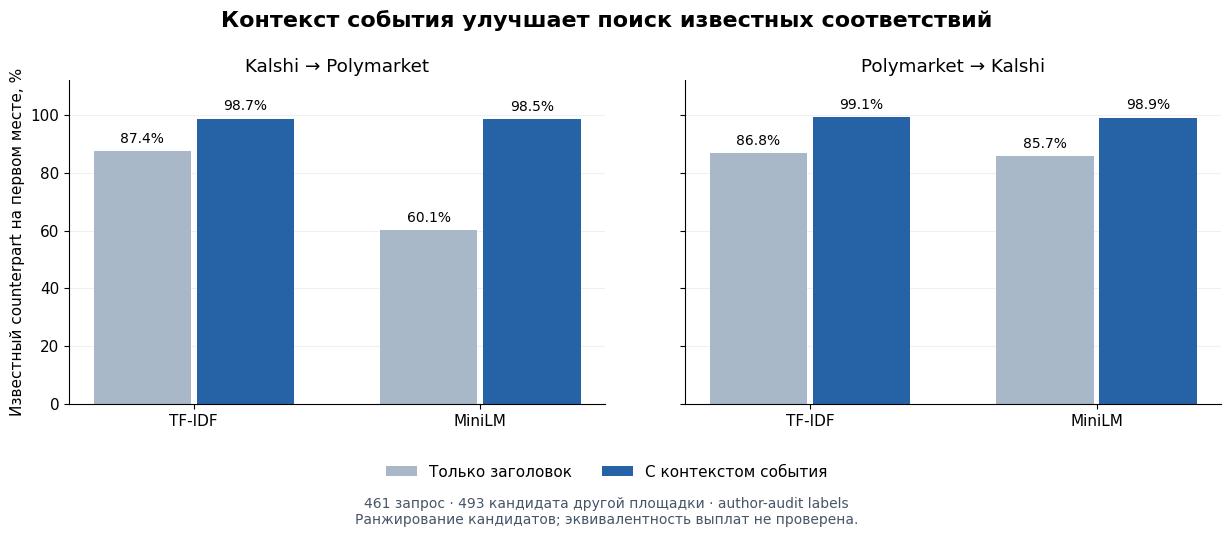

График сохранён: output/pilot_v2_retrieval.png


In [3]:
# Статический исследовательский график: сохранённые доли, без нового inference.
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4), sharey=True)
x = np.arange(2)
for ax, venue, title in zip(axes, ['kalshi', 'poly'],
                          ['Kalshi → Polymarket', 'Polymarket → Kalshi']):
    for offset, view, label, color in [(-0.18, 'title', 'Только заголовок', '#a9b8c8'),
                                     (0.18, 'event_title', 'С контекстом события', '#2563a6')]:
        values = [100 * lookup[m, view, venue]['at_k']['1']['query_hit_rate']
                  for m in ['lexical', 'dense']]
        bars = ax.bar(x + offset, values, width=0.34, color=color, label=label)
        ax.bar_label(bars, labels=[f'{v:.1f}%' for v in values], padding=4, fontsize=10)
    ax.set(title=title, xticks=x, xticklabels=['TF-IDF', 'MiniLM'], ylim=(0, 112))
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(axis='y', alpha=0.18)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Известный counterpart на первом месте, %')
fig.suptitle('Контекст события улучшает поиск известных соответствий',
             fontsize=16, fontweight='bold', y=0.98)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.085),
           ncol=2, frameon=False)
fig.text(0.5, 0.028, '461 запрос · 493 кандидата другой площадки · author-audit labels\n'
         'Ранжирование кандидатов; эквивалентность выплат не проверена.',
         ha='center', fontsize=10, color='#475569')
fig.subplots_adjust(top=0.85, bottom=0.25, left=0.08, right=0.98, wspace=0.15)
chart_path = ROOT / 'output/pilot_v2_retrieval.png'
chart_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(chart_path, dpi=180, facecolor='white')
plt.show()
plt.close(fig)
print('График сохранён:', chart_path.relative_to(ROOT))

In [4]:
display(Markdown('### 3. Один понятный пример: Good Afternoon, ранг 21 → 1'))
ticker = 'KXFEDMENTION-26SEP-GOOD'
example = next(p for p in pairs if p['kalshi_ticker'] == ticker)
dense_title = load('redesign/retrieval/dense_title_pair_ranks.json')
dense_context = load('redesign/retrieval/dense_event_title_pair_ranks.json')
rank_before = next(p for p in dense_title if p['kalshi_ticker'] == ticker)['poly_rank_for_kalshi']
rank_after = next(p for p in dense_context if p['kalshi_ticker'] == ticker)['poly_rank_for_kalshi']
assert (rank_before, rank_after) == (21, 1)
display(pd.DataFrame([
    {'Поле': 'Запрос Kalshi', 'Текст': example['kalshi_title']},
    {'Поле': 'Короткая строка Polymarket', 'Текст': example['poly_title']},
    {'Поле': 'Название события Polymarket', 'Текст': example['poly_event_title']},
]).set_index('Поле'))
print(f'Ранг известной авторской пары: {rank_before} → {rank_after}')
display(Markdown('«Good Afternoon» — короткий вариант ответа, который теряет смысл '
    'без события пресс-конференции. Это особенность полей данного snapshot; '
    'её нельзя автоматически переносить на canonical question всех рынков. '
    'Пример выбран после запуска для объяснения результата, а не как отдельный тест. '
    'Авторская метка same не заменяет чтение полных правил.'))

### 3. Один понятный пример: Good Afternoon, ранг 21 → 1

,Текст
Поле,
Запрос Kalshi,Will Kevin Warsh say Good Afternoon at his Sep...
Короткая строка Polymarket,Good Afternoon
Название события Polymarket,What will Kevin Warsh say during September Pre...


Ранг известной авторской пары: 21 → 1


«Good Afternoon» — короткий вариант ответа, который теряет смысл без события пресс-конференции. Это особенность полей данного snapshot; её нельзя автоматически переносить на canonical question всех рынков. Пример выбран после запуска для объяснения результата, а не как отдельный тест. Авторская метка same не заменяет чтение полных правил.

In [5]:
display(Markdown('### 4. Почему найденная пара ещё не подтверждена'))
negatives = [p for p in dense_context if p['reference_label'] == 'different']
assert len(negatives) == 27
negative_rows = []
for field, direction in [('poly_rank_for_kalshi', 'Kalshi → Polymarket'),
                         ('kalshi_rank_for_poly', 'Polymarket → Kalshi')]:
    negative_rows.append({'Направление': direction,
        'Авторский different в top-1': sum(p[field] <= 1 for p in negatives),
        'В top-5': sum(p[field] <= 5 for p in negatives), 'Всего': len(negatives)})
assert negative_rows[0]['Авторский different в top-1'] == 24
assert negative_rows[0]['В top-5'] == 27
display(pd.DataFrame(negative_rows).set_index('Направление'))
display(Markdown('У MiniLM с контекстом **24 из 27** авторских different-пар '
    'стоят первыми в направлении Kalshi → Polymarket, все **27** попадают в top-5. '
    'Они семантически близки и могут быть полезными кандидатами второй стадии. '
    '**Это не false-positive rate классификации:** reject-правило или '
    'классификатор отношений здесь не применялись. Ошибкой было бы автоматически '
    'объявить ближайший контракт эквивалентным.'))

### 4. Почему найденная пара ещё не подтверждена

,Авторский different в top-1,В top-5,Всего
Направление,,,
Kalshi → Polymarket,24,27,27
Polymarket → Kalshi,20,26,27


У MiniLM с контекстом **24 из 27** авторских different-пар стоят первыми в направлении Kalshi → Polymarket, все **27** попадают в top-5. Они семантически близки и могут быть полезными кандидатами второй стадии. **Это не false-positive rate классификации:** reject-правило или классификатор отношений здесь не применялись. Ошибкой было бы автоматически объявить ближайший контракт эквивалентным.

In [6]:
display(Markdown('### 5. Три предварительные политические карточки'))
card_names = ['politics_resignation_departure', 'politics_impeachment_departure',
              'politics_crossvenue_departure']
explanations = {
    'politics_resignation_departure': 'При общих предпосылках объявление отставки '
        'влечёт квалифицирующий уход; обратное не обязательно.',
    'politics_impeachment_departure': 'Импичмент и уход не влекут друг друга; '
        'в заявленной области рассмотрены все четыре бинарных сочетания.',
    'politics_crossvenue_departure': 'У Kalshi есть расчёт по последней цене или '
        'справедливому распределению при уходе вследствие смерти: общая модель '
        'только Да/Нет неполна.'}
for name in card_names:
    card = load('redesign/cards/' + name + '.json')
    display(Markdown('**' + name + '** — ' + explanations[name] + '\n\n'
        '*Сохранённый вывод:* ' + card['conclusion'] + '\n\n'
        'Статус: `' + card['review']['status'] + '`. Покрытие источников: `'
        + card['scope']['source_coverage'] + '`.'))
display(Markdown('Это разборы текста с явными предпосылками, не независимый gold '
    'и не результат классификатора. Политические правила Polymarket сохранены '
    'через стороннюю копию; правила Kalshi — через официальный API. Небинарная '
    'ветвь делает общую таблицу неполной, но сама по себе не запрещает изучать '
    'обычные бинарные сценарии. Статистическая корреляция цен здесь не измерялась.'))

### 5. Три предварительные политические карточки

**politics_resignation_departure** — При общих предпосылках объявление отставки влечёт квалифицирующий уход; обратное не обязательно.

*Сохранённый вывод:* Conditional A⇒B, not equivalence. The conclusion applies to the saved textual predicates under the stated reporting assumptions.

Статус: `ai_assisted_provisional`. Покрытие источников: `resolution_text_only`.

**politics_impeachment_departure** — Импичмент и уход не влекут друг друга; в заявленной области рассмотрены все четыре бинарных сочетания.

*Сохранённый вывод:* All four states have textual witnesses in the declared scope: no strict logical relation. This says nothing about statistical correlation.

Статус: `ai_assisted_provisional`. Покрытие источников: `resolution_text_only`.

**politics_crossvenue_departure** — У Kalshi есть расчёт по последней цене или справедливому распределению при уходе вследствие смерти: общая модель только Да/Нет неполна.

*Сохранённый вывод:* Binary equivalence is unsupported. The concrete obstruction is a payout-domain mismatch, in addition to an announcement-horizon difference.

Статус: `ai_assisted_provisional`. Покрытие источников: `partial_or_conflicting`.

Это разборы текста с явными предпосылками, не независимый gold и не результат классификатора. Политические правила Polymarket сохранены через стороннюю копию; правила Kalshi — через официальный API. Небинарная ветвь делает общую таблицу неполной, но сама по себе не запрещает изучать обычные бинарные сценарии. Статистическая корреляция цен здесь не измерялась.

In [7]:
display(Markdown('### 6. Ещё шесть кандидатов: snapshot без утверждённых меток'))
candidates = load('redesign/discovery/official_probe/candidate_pairs.json')
records = {r['id']: r for r in load('redesign/discovery/official_probe/source_records.json')}
assert len(candidates) == 6
assert all(p['adjudicated_label'] is None and p['do_not_use_as_gold'] for p in candidates)
for p in candidates:
    source_kinds = sorted({records[p[side]]['source_kind'] for side in ['a', 'b']})
    display(Markdown('**' + p['case_id'] + '** (' + p['domain'] + ') — '
        + p['question_ru'] + '\n\n' + p['research_note_ru'] + '\n\n'
        'Источники: `' + '`, `'.join(source_kinds) + '`. Метка: **не установлена**.'))
display(Markdown('**Что можно защищать сейчас:** контекст восстановил известные '
    'связи в фиксированном наборе; простой поиск оказался конкурентоспособным; '
    'близость текста не подтверждает отношение выплат. Следующий эксперимент '
    'проверяет правила и контрсценарии на новом наборе с независимой разметкой. '
    'Шесть кандидатов выше — материал для такой проверки, не шесть доказанных связей.'))
print('Готово: локальные результаты прочитаны, исходный SHA-256 проверен; модели не запускались.')

### 6. Ещё шесть кандидатов: snapshot без утверждённых меток

**macro_recession_definition** (macroeconomics) — Одно слово recession, разные операционные определения: два отрицательных GDP-квартала против квартала business-cycle peak по NBER.

Не выводить логическую связь из названия или тикера. KXRECSSNBER-26 несмотря на NBER в ID использует GDP в primary; второй контракт использует решение NBER и quarter clarification.

Источники: `official_live_api`. Метка: **не установлена**.

**macro_hike_unit_and_window** (macroeconomics) — Хотя оба контракта о Fed hike, один спрашивает наличие повышения после issuance, другой — ровно одну единицу повышения за календарный год.

Secondary второго считает 26–50 bp как два hikes. Нельзя заменить числом заседаний. Primary первого отсчитывает окно от issuance, не от начала 2026.

Источники: `official_live_api`. Метка: **не установлена**.

**gaming_release_vs_postponement** (gaming) — Кажущиеся противоположности: выпущена к May26 и postponed byMay26.

Polymarket имеет OR: официальное объявление переноса ИЛИ фактический невыпуск. Объявление, позже отозванное, допускает иной результат, чем чистое отрицание факта выпуска. Kalshi ограничивает major platforms, Polymarket определяет публичные purchase/download и исключает early access.

Источники: `official_historical_api`, `official_website_search_index`. Метка: **не установлена**.

**gaming_base_game_vs_online** (gaming) — Похожие названия GTA VI release: base-game release в октябре против онлайн-сервиса до2027.

Kalshi явно допускает bundled или separately distributed multiplayer service, независимо от имени. Polymarket basegame покупка/загрузка вUS, исключены early access/beta/leaks; даты также различаются. Не подменять different product тематической похожестью.

Источники: `official_live_api`, `official_website_search_index`. Метка: **не установлена**.

**sports_world_to_league** (sports) — Dodgers World Series champion против Dodgers National League champion.

Ожидаемая спортивная вложенность зависит от структуры турнира; payout rules содержат разные deadline/cancellation clauses. В NLCS опубликовано November31,2026 — несуществующая дата: сохранить и отправить на уточнение.

Источники: `official_website_search_index`. Метка: **не установлена**.

**sports_world_vs_other_league_winner** (sports) — Dodgers World Series champion против Atlanta Braves National League champion.

При стандартном маршруте MLB кандидат на несовместимость, но это требует внешней структуры турнира и проверки exceptions. Не объявлять независимость и не исправлять November31 из NLCS rules.

Источники: `official_website_search_index`. Метка: **не установлена**.

**Что можно защищать сейчас:** контекст восстановил известные связи в фиксированном наборе; простой поиск оказался конкурентоспособным; близость текста не подтверждает отношение выплат. Следующий эксперимент проверяет правила и контрсценарии на новом наборе с независимой разметкой. Шесть кандидатов выше — материал для такой проверки, не шесть доказанных связей.

Готово: локальные результаты прочитаны, исходный SHA-256 проверен; модели не запускались.
